In [1]:
import os
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

X_train, y_train, X_test, y_test = joblib.load("../data/processed/data_processed.joblib")
print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Part d'attaques - train :", round(y_train.mean(), 3), "| test :", round(y_test.mean(), 3))

Train : (175341, 60) | Test : (82332, 60)
Part d'attaques - train : 0.681 | test : 0.551


In [2]:
resultats = []  
os.makedirs("../docs/figures", exist_ok=True)


def evaluer(nom, modele, duree_entrainement=None):
    """Évalue un modèle sur le jeu de test et ajoute une ligne au tableau comparatif."""
    pred = modele.predict(X_test)
    if hasattr(modele, "predict_proba"):
        score = modele.predict_proba(X_test)[:, 1]
    elif hasattr(modele, "decision_function"):
        score = modele.decision_function(X_test)
    else:
        score = pred

    ligne = {
        "Modèle": nom,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, score),
    }
    if duree_entrainement is not None:
        ligne["Temps (s)"] = round(duree_entrainement, 1)

    resultats[:] = [r for r in resultats if r["Modèle"] != nom]  # évite les doublons si on relance
    resultats.append(ligne)
    return pred, score


def afficher_matrice(nom, pred):
    """Dessine et enregistre la matrice de confusion."""
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Normal", "Attaque"], cmap="Blues", values_format="d"
    )
    plt.title(f"Matrice de confusion - {nom}")
    plt.savefig(f"../docs/figures/matrice_{nom.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()

Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
Zero-R    0.5506     0.5506     1.0 0.7102      0.5        0.1


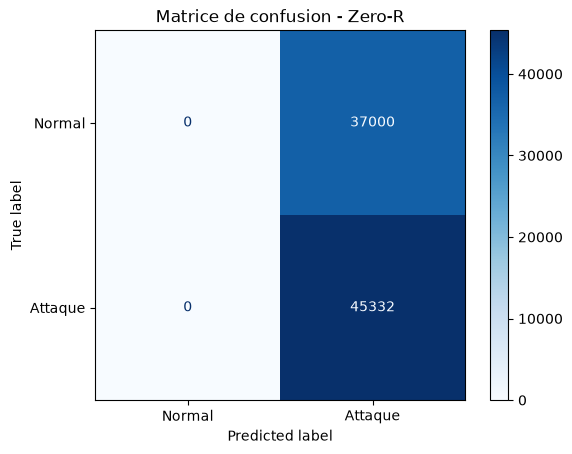

In [3]:
from sklearn.dummy import DummyClassifier

debut = time.time()
zero_r = DummyClassifier(strategy="most_frequent")
zero_r.fit(X_train, y_train)
pred, score = evaluer("Zero-R", zero_r, time.time() - debut)

print(pd.DataFrame(resultats).round(4).to_string(index=False))
afficher_matrice("Zero-R", pred)

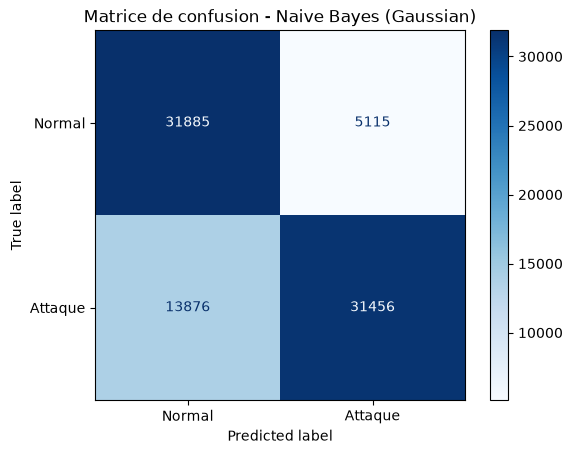

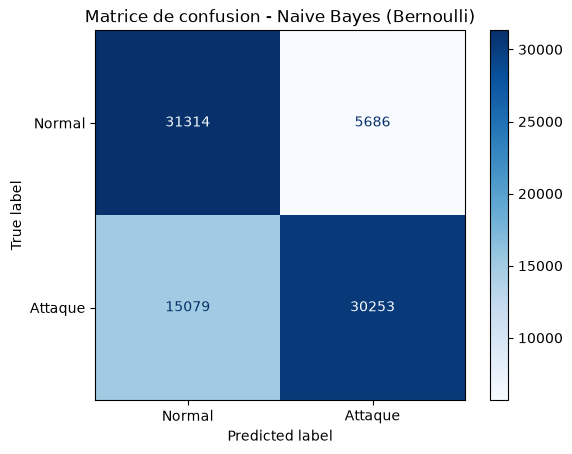

                 Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                 Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
 Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1


In [4]:
from sklearn.naive_bayes import BernoulliNB, GaussianNB

debut = time.time()
nb_gauss = GaussianNB()
nb_gauss.fit(X_train, y_train)
pred, score = evaluer("Naive Bayes (Gaussian)", nb_gauss, time.time() - debut)
afficher_matrice("Naive Bayes (Gaussian)", pred)

debut = time.time()
nb_bern = BernoulliNB(alpha=1.0)  # alpha = 1 : lissage de Laplace
nb_bern.fit(X_train, y_train)
pred, score = evaluer("Naive Bayes (Bernoulli)", nb_bern, time.time() - debut)
afficher_matrice("Naive Bayes (Bernoulli)", pred)

print(pd.DataFrame(resultats).round(4).to_string(index=False))

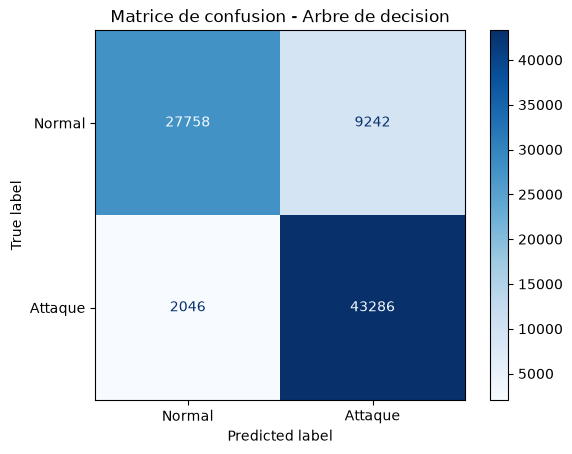

Profondeur : 42 | Feuilles : 5699
Accuracy train : 0.9982 | test : 0.8629
                 Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                 Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
 Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1
      Arbre de decision    0.8629     0.8241  0.9549 0.8847   0.8550        3.3


In [5]:
from sklearn.tree import DecisionTreeClassifier

debut = time.time()
arbre = DecisionTreeClassifier(criterion="gini", random_state=42)  # sans limite de profondeur
arbre.fit(X_train, y_train)
duree = time.time() - debut
pred, score = evaluer("Arbre de decision", arbre, duree)
afficher_matrice("Arbre de decision", pred)

print("Profondeur :", arbre.get_depth(), "| Feuilles :", arbre.get_n_leaves())
print("Accuracy train :", round(arbre.score(X_train, y_train), 4),
      "| test :", round(arbre.score(X_test, y_test), 4))
print(pd.DataFrame(resultats).round(4).to_string(index=False))

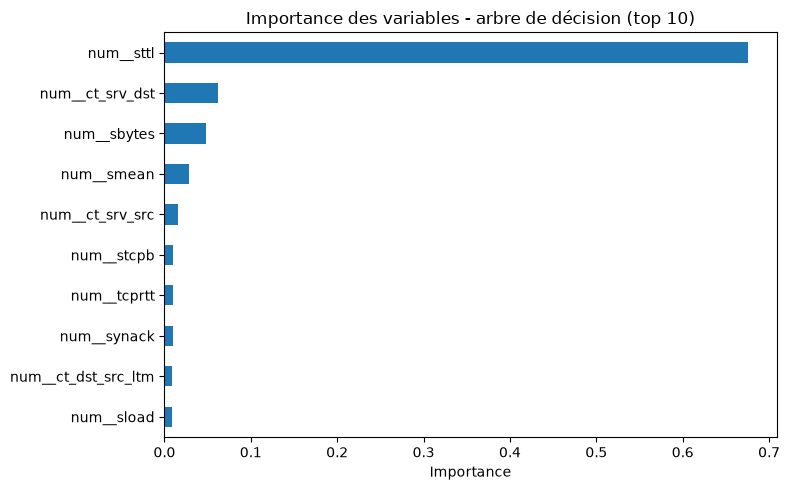

In [6]:
preprocesseur = joblib.load("../models/preprocessor.joblib")
noms = preprocesseur.get_feature_names_out()
importances = pd.Series(arbre.feature_importances_, index=noms).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
importances[::-1].plot(kind="barh", color="#1f77b4")
plt.title("Importance des variables - arbre de décision (top 10)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("../docs/figures/importance_arbre.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(resultats).round(4).to_csv("../docs/resultats_modeles.csv", index=False)

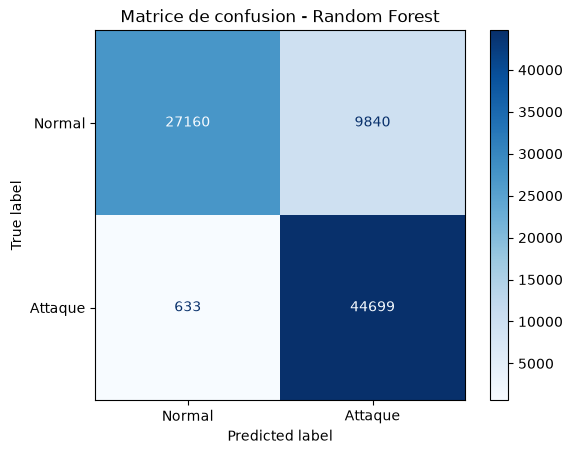

Accuracy train : 0.9982 | test : 0.8728
                 Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                 Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
 Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1
      Arbre de decision    0.8629     0.8241  0.9549 0.8847   0.8550        3.3
          Random Forest    0.8728     0.8196  0.9860 0.8951   0.9796       21.2


In [7]:
from sklearn.ensemble import RandomForestClassifier

debut = time.time()
foret = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
foret.fit(X_train, y_train)
duree = time.time() - debut
pred, score = evaluer("Random Forest", foret, duree)
afficher_matrice("Random Forest", pred)

print("Accuracy train :", round(foret.score(X_train, y_train), 4),
      "| test :", round(foret.score(X_test, y_test), 4))
print(pd.DataFrame(resultats).round(4).to_string(index=False))

pd.DataFrame(resultats).round(4).to_csv("../docs/resultats_modeles.csv", index=False)

In [8]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_train, y_train)

debut = time.time()
_ = knn.predict_proba(X_test[:2000])
t_2000 = time.time() - debut
print(f"2000 lignes : {t_2000:.1f} s")
print(f"Estimation pour {len(X_test)} lignes : {t_2000 * len(X_test) / 2000 / 60:.1f} min")

2000 lignes : 1.2 s
Estimation pour 82332 lignes : 0.8 min


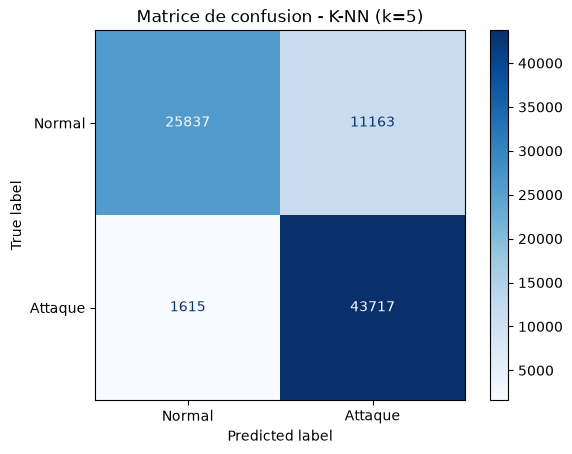

                 Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                 Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
 Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1
      Arbre de decision    0.8629     0.8241  0.9549 0.8847   0.8550        3.3
          Random Forest    0.8728     0.8196  0.9860 0.8951   0.9796       21.2
             K-NN (k=5)    0.8448     0.7966  0.9644 0.8725   0.9315       41.1


In [9]:
def evaluer_scores(nom, pred, score, duree=None):
    """Comme evaluer(), mais à partir de scores déjà calculés (évite de refaire les voisins deux fois)."""
    ligne = {
        "Modèle": nom,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, score),
    }
    if duree is not None:
        ligne["Temps (s)"] = round(duree, 1)
    resultats[:] = [r for r in resultats if r["Modèle"] != nom]
    resultats.append(ligne)


debut = time.time()
score = knn.predict_proba(X_test)[:, 1]
pred = (score >= 0.5).astype(int)
duree = time.time() - debut

evaluer_scores("K-NN (k=5)", pred, score, duree)
afficher_matrice("K-NN (k=5)", pred)

print(pd.DataFrame(resultats).round(4).to_string(index=False))
pd.DataFrame(resultats).round(4).to_csv("../docs/resultats_modeles.csv", index=False)

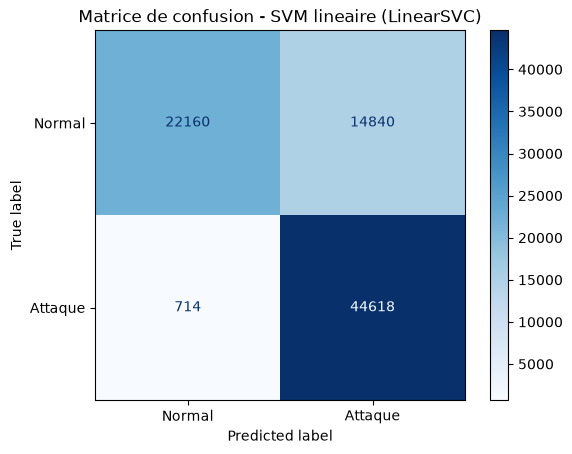

                  Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                  Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
  Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
 Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1
       Arbre de decision    0.8629     0.8241  0.9549 0.8847   0.8550        3.3
           Random Forest    0.8728     0.8196  0.9860 0.8951   0.9796       21.2
              K-NN (k=5)    0.8448     0.7966  0.9644 0.8725   0.9315       41.1
SVM lineaire (LinearSVC)    0.8111     0.7504  0.9842 0.8516   0.9537        9.9


In [10]:
from sklearn.svm import LinearSVC

debut = time.time()
svm_lin = LinearSVC(C=1.0, dual=False, random_state=42)
svm_lin.fit(X_train, y_train)
duree = time.time() - debut

pred, score = evaluer("SVM lineaire (LinearSVC)", svm_lin, duree)
afficher_matrice("SVM lineaire (LinearSVC)", pred)
print(pd.DataFrame(resultats).round(4).to_string(index=False))
pd.DataFrame(resultats).round(4).to_csv("../docs/resultats_modeles.csv", index=False)

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X_sub, _, y_sub, _ = train_test_split(
    X_train, y_train, train_size=5000, stratify=y_train, random_state=42
)

debut = time.time()
svm_test = SVC(kernel="rbf", C=1.0, gamma="scale")
svm_test.fit(X_sub, y_sub)
t_fit = time.time() - debut

debut = time.time()
_ = svm_test.predict(X_test[:2000])
t_pred = time.time() - debut

print(f"Entrainement sur 5000 lignes : {t_fit:.1f} s")
print(f"Estimation (approximative) sur 20000 lignes : {t_fit * 16 / 60:.1f} min")
print(f"Prediction de 2000 lignes : {t_pred:.1f} s")

Entrainement sur 5000 lignes : 0.3 s
Estimation (approximative) sur 20000 lignes : 0.1 min
Prediction de 2000 lignes : 0.2 s


Entrainement : 48.3 s
Prediction : 53.9 s


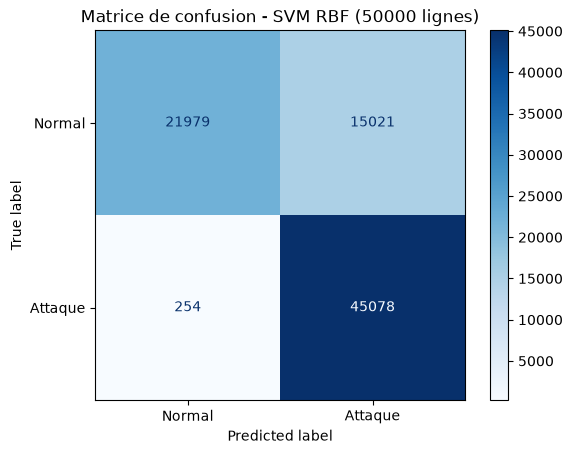

                  Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                  Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
  Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
 Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1
       Arbre de decision    0.8629     0.8241  0.9549 0.8847   0.8550        3.3
           Random Forest    0.8728     0.8196  0.9860 0.8951   0.9796       21.2
              K-NN (k=5)    0.8448     0.7966  0.9644 0.8725   0.9315       41.1
SVM lineaire (LinearSVC)    0.8111     0.7504  0.9842 0.8516   0.9537        9.9
  SVM RBF (50000 lignes)    0.8145     0.7501  0.9944 0.8551   0.9574      102.2


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X_sub, _, y_sub, _ = train_test_split(
    X_train, y_train, train_size=50000, stratify=y_train, random_state=42
)

debut = time.time()
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale")
svm_rbf.fit(X_sub, y_sub)
duree_fit = time.time() - debut
print(f"Entrainement : {duree_fit:.1f} s")

debut = time.time()
score = svm_rbf.decision_function(X_test)   # un seul passage sur le jeu de test
pred = (score > 0).astype(int)
duree_pred = time.time() - debut
print(f"Prediction : {duree_pred:.1f} s")

evaluer_scores("SVM RBF (50000 lignes)", pred, score, duree_fit + duree_pred)
afficher_matrice("SVM RBF (50000 lignes)", pred)
print(pd.DataFrame(resultats).round(4).to_string(index=False))
pd.DataFrame(resultats).round(4).to_csv("../docs/resultats_modeles.csv", index=False)

In [13]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, train_test_split

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
recherches = []  # un résumé par optimisation


def sous_echantillon(n):
    """Tire n lignes du train en gardant la même part d'attaques."""
    X_s, _, y_s, _ = train_test_split(X_train, y_train, train_size=n, stratify=y_train, random_state=42)
    return X_s, y_s


def resumer_recherche(nom, recherche):
    meilleur = recherche.best_params_
    print(f"{nom} - meilleurs hyperparametres : {meilleur}")
    print(f"{nom} - F1 moyen en validation croisee (5 plis) : {recherche.best_score_:.4f}")
    recherches[:] = [r for r in recherches if r["Modèle"] != nom]
    recherches.append({
        "Modèle": nom,
        "Meilleurs hyperparamètres": str(meilleur),
        "F1 validation croisée": round(recherche.best_score_, 4),
    })
    pd.DataFrame(recherches).to_csv("../docs/optimisation_cv.csv", index=False)

Arbre de decision - meilleurs hyperparametres : {'criterion': 'entropy', 'max_depth': 20, 'min_samples_leaf': 1}
Arbre de decision - F1 moyen en validation croisee (5 plis) : 0.9638
Duree de la recherche : 162 s


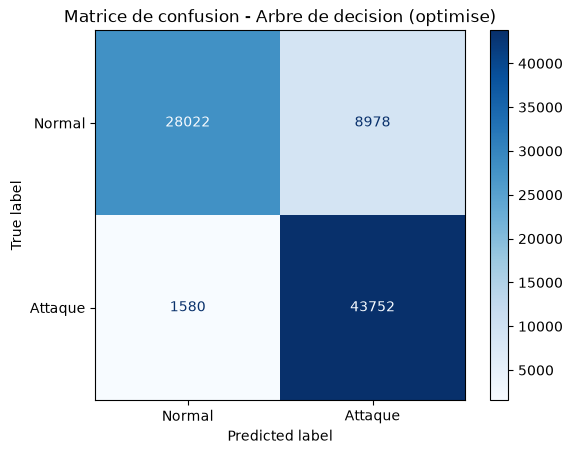

,param_criterion,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score,rank_test_score
36,entropy,20,1,0.963800,0.000741,1
12,gini,20,1,0.963467,0.000837,2
8,gini,15,1,0.963347,0.001345,3
44,entropy,None,1,0.963173,0.000602,4
9,gini,15,5,0.963110,0.000947,5
19,gini,30,50,0.963031,0.000777,6
23,gini,None,50,0.963031,0.000777,6
37,entropy,20,5,0.963015,0.000703,8
40,entropy,30,1,0.962984,0.000880,9
14,gini,20,20,0.962951,0.000664,10


In [14]:
from sklearn.tree import DecisionTreeClassifier

grille_arbre = {
    "criterion": ["gini", "entropy"],          # Gini ou gain d'information
    "max_depth": [5, 10, 15, 20, 30, None],    # profondeur maximale (élagage)
    "min_samples_leaf": [1, 5, 20, 50],        # taille minimale d'une feuille (élagage)
}

debut = time.time()
rech_arbre = GridSearchCV(DecisionTreeClassifier(random_state=42), grille_arbre,
                          scoring="f1", cv=cv5, n_jobs=-1)
rech_arbre.fit(X_train, y_train)
duree = time.time() - debut
resumer_recherche("Arbre de decision", rech_arbre)
print(f"Duree de la recherche : {duree:.0f} s")

pred, score = evaluer("Arbre de decision (optimise)", rech_arbre.best_estimator_, duree)
afficher_matrice("Arbre de decision (optimise)", pred)

res = pd.DataFrame(rech_arbre.cv_results_)
res[["param_criterion", "param_max_depth", "param_min_samples_leaf",
     "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").head(10)

In [15]:
from sklearn.naive_bayes import BernoulliNB, GaussianNB

# Gaussian : le lissage s'appelle var_smoothing
rech_gauss = GridSearchCV(GaussianNB(),
                          {"var_smoothing": [1e-11, 1e-10, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5]},
                          scoring="f1", cv=cv5, n_jobs=-1).fit(X_train, y_train)
resumer_recherche("Naive Bayes (Gaussian)", rech_gauss)
pred, score = evaluer("Naive Bayes Gaussian (optimise)", rech_gauss.best_estimator_)

# Bernoulli : alpha = 1 correspond au lissage de Laplace
rech_bern = GridSearchCV(BernoulliNB(),
                         {"alpha": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]},
                         scoring="f1", cv=cv5, n_jobs=-1).fit(X_train, y_train)
resumer_recherche("Naive Bayes (Bernoulli)", rech_bern)
pred, score = evaluer("Naive Bayes Bernoulli (optimise)", rech_bern.best_estimator_)

print(pd.DataFrame(resultats).round(4).to_string(index=False))

Naive Bayes (Gaussian) - meilleurs hyperparametres : {'var_smoothing': 1e-05}
Naive Bayes (Gaussian) - F1 moyen en validation croisee (5 plis) : 0.8078
Naive Bayes (Bernoulli) - meilleurs hyperparametres : {'alpha': 0.01}
Naive Bayes (Bernoulli) - F1 moyen en validation croisee (5 plis) : 0.7813
                          Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                          Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
          Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
         Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1
               Arbre de decision    0.8629     0.8241  0.9549 0.8847   0.8550        3.3
                   Random Forest    0.8728     0.8196  0.9860 0.8951   0.9796       21.2
                      K-NN (k=5)    0.8448     0.7966  0.9644 0.8725   0.9315       41.1
        SVM lineaire (LinearSVC)    0.8111     0.7504  0.9842 0.8516   0.9537   

K-NN (sous-echantillon 20000) - meilleurs hyperparametres : {'metric': 'manhattan', 'n_neighbors': 21, 'weights': 'distance'}
K-NN (sous-echantillon 20000) - F1 moyen en validation croisee (5 plis) : 0.9568
Duree de la recherche : 57 s


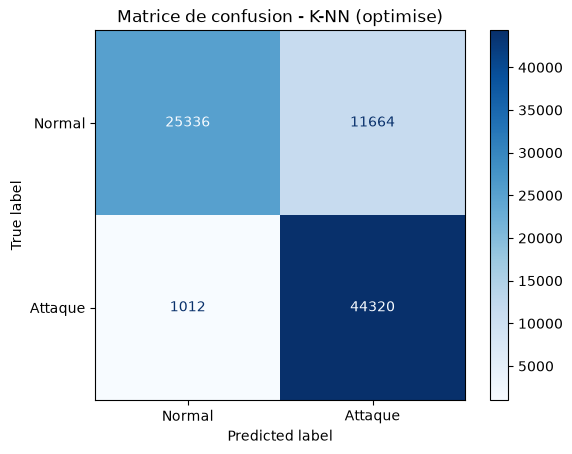

                          Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                          Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
          Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
         Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1
               Arbre de decision    0.8629     0.8241  0.9549 0.8847   0.8550        3.3
                   Random Forest    0.8728     0.8196  0.9860 0.8951   0.9796       21.2
                      K-NN (k=5)    0.8448     0.7966  0.9644 0.8725   0.9315       41.1
        SVM lineaire (LinearSVC)    0.8111     0.7504  0.9842 0.8516   0.9537        9.9
          SVM RBF (50000 lignes)    0.8145     0.7501  0.9944 0.8551   0.9574      102.2
    Arbre de decision (optimise)    0.8718     0.8297  0.9651 0.8923   0.9135      162.1
 Naive Bayes Gaussian (optimise)    0.7693     0.8601  0.6939 0.7681   0.8698        NaN
Naive Bayes Bernoulli

In [16]:
X_s, y_s = sous_echantillon(20000)

grille_knn = {
    "n_neighbors": [3, 5, 11, 21, 41],            # le K
    "metric": ["euclidean", "manhattan"],         # distance
    "weights": ["uniform", "distance"],           # voisins de poids égal ou pondérés par la proximité
}

debut = time.time()
rech_knn = GridSearchCV(KNeighborsClassifier(), grille_knn, scoring="f1", cv=cv5, n_jobs=-1)
rech_knn.fit(X_s, y_s)
resumer_recherche("K-NN (sous-echantillon 20000)", rech_knn)
print(f"Duree de la recherche : {time.time() - debut:.0f} s")

# Réentraînement du meilleur réglage sur tout le train, puis évaluation unique sur le test
knn_opt = KNeighborsClassifier(**rech_knn.best_params_, n_jobs=-1).fit(X_train, y_train)
debut = time.time()
score = knn_opt.predict_proba(X_test)[:, 1]
pred = (score >= 0.5).astype(int)
evaluer_scores("K-NN (optimise)", pred, score, time.time() - debut)
afficher_matrice("K-NN (optimise)", pred)

print(pd.DataFrame(resultats).round(4).to_string(index=False))
pd.DataFrame(resultats).round(4).to_csv("../docs/resultats_modeles.csv", index=False)

Random Forest (sous-echantillon 40000) - meilleurs hyperparametres : {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 30, 'class_weight': None}
Random Forest (sous-echantillon 40000) - F1 moyen en validation croisee (5 plis) : 0.9639
Duree de la recherche : 146 s


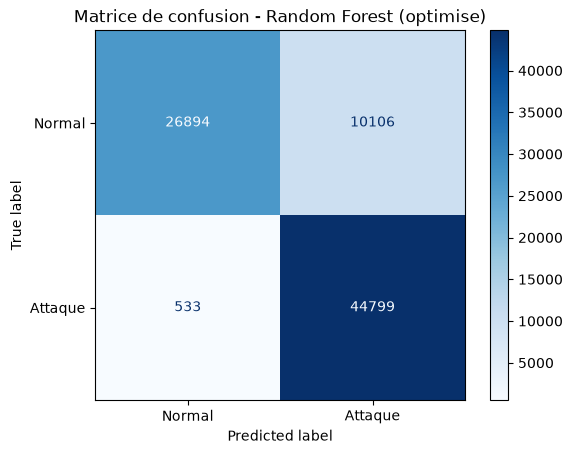

                          Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                          Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
          Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
         Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1
               Arbre de decision    0.8629     0.8241  0.9549 0.8847   0.8550        3.3
                   Random Forest    0.8728     0.8196  0.9860 0.8951   0.9796       21.2
                      K-NN (k=5)    0.8448     0.7966  0.9644 0.8725   0.9315       41.1
        SVM lineaire (LinearSVC)    0.8111     0.7504  0.9842 0.8516   0.9537        9.9
          SVM RBF (50000 lignes)    0.8145     0.7501  0.9944 0.8551   0.9574      102.2
    Arbre de decision (optimise)    0.8718     0.8297  0.9651 0.8923   0.9135      162.1
 Naive Bayes Gaussian (optimise)    0.7693     0.8601  0.6939 0.7681   0.8698        NaN
Naive Bayes Bernoulli

In [17]:
from sklearn.ensemble import RandomForestClassifier

X_s, y_s = sous_echantillon(40000)

distributions_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, 30, None],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
    "class_weight": [None, "balanced"],
}

debut = time.time()
rech_rf = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=42),
    distributions_rf, n_iter=12, scoring="f1", cv=cv5, random_state=42, n_jobs=1,
)
rech_rf.fit(X_s, y_s)
resumer_recherche("Random Forest (sous-echantillon 40000)", rech_rf)
print(f"Duree de la recherche : {time.time() - debut:.0f} s")

# Réentraînement du meilleur réglage sur tout le train, puis évaluation unique sur le test
debut = time.time()
rf_opt = RandomForestClassifier(**rech_rf.best_params_, n_jobs=-1, random_state=42)
rf_opt.fit(X_train, y_train)
pred, score = evaluer("Random Forest (optimise)", rf_opt, time.time() - debut)
afficher_matrice("Random Forest (optimise)", pred)

print(pd.DataFrame(resultats).round(4).to_string(index=False))
pd.DataFrame(resultats).round(4).to_csv("../docs/resultats_modeles.csv", index=False)

In [18]:
from sklearn.svm import SVC

X_s, y_s = sous_echantillon(6000)

grille_svm = [
    {"kernel": ["rbf"], "C": [0.1, 1, 10, 100], "gamma": ["scale", 0.001, 0.01, 0.1]},
    {"kernel": ["linear"], "C": [0.1, 1]},
    {"kernel": ["poly"], "C": [1, 10], "degree": [2, 3], "gamma": ["scale"]},
]

debut = time.time()
rech_svm = GridSearchCV(SVC(cache_size=1000), grille_svm, scoring="f1", cv=cv5, n_jobs=-1)
rech_svm.fit(X_s, y_s)
resumer_recherche("SVM (sous-echantillon 6000)", rech_svm)
print(f"Duree de la recherche : {time.time() - debut:.0f} s")

res = pd.DataFrame(rech_svm.cv_results_)
res[["param_kernel", "param_C", "param_gamma", "param_degree",
     "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").head(10)

SVM (sous-echantillon 6000) - meilleurs hyperparametres : {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
SVM (sous-echantillon 6000) - F1 moyen en validation croisee (5 plis) : 0.9559
Duree de la recherche : 41 s


,param_kernel,param_C,param_gamma,param_degree,mean_test_score,std_test_score,rank_test_score
10,rbf,10.0,0.01,NaN,0.955869,0.006188,1
4,rbf,1.0,scale,NaN,0.955706,0.006146,2
7,rbf,1.0,0.1,NaN,0.955133,0.006129,3
21,poly,10.0,scale,3.0,0.955031,0.006324,4
14,rbf,100.0,0.01,NaN,0.954837,0.004207,5
20,poly,10.0,scale,2.0,0.954750,0.006829,6
8,rbf,10.0,scale,NaN,0.954679,0.005569,7
6,rbf,1.0,0.01,NaN,0.954376,0.006788,8
18,poly,1.0,scale,2.0,0.954349,0.006626,9
17,linear,1.0,NaN,NaN,0.954312,0.005519,10


Entrainement : 45.9 s
Prediction : 56.9 s


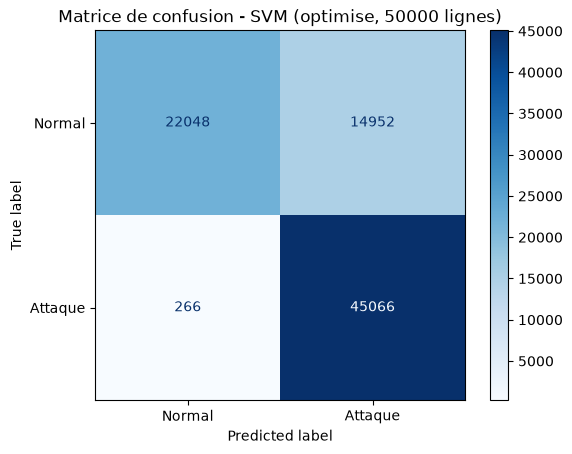

                          Modèle  Accuracy  Precision  Recall     F1  ROC-AUC  Temps (s)
                          Zero-R    0.5506     0.5506  1.0000 0.7102   0.5000        0.1
          Naive Bayes (Gaussian)    0.7693     0.8601  0.6939 0.7681   0.8698        0.2
         Naive Bayes (Bernoulli)    0.7478     0.8418  0.6674 0.7445   0.8173        0.1
               Arbre de decision    0.8629     0.8241  0.9549 0.8847   0.8550        3.3
                   Random Forest    0.8728     0.8196  0.9860 0.8951   0.9796       21.2
                      K-NN (k=5)    0.8448     0.7966  0.9644 0.8725   0.9315       41.1
        SVM lineaire (LinearSVC)    0.8111     0.7504  0.9842 0.8516   0.9537        9.9
          SVM RBF (50000 lignes)    0.8145     0.7501  0.9944 0.8551   0.9574      102.2
    Arbre de decision (optimise)    0.8718     0.8297  0.9651 0.8923   0.9135      162.1
 Naive Bayes Gaussian (optimise)    0.7693     0.8601  0.6939 0.7681   0.8698        NaN
Naive Bayes Bernoulli

In [19]:
X_sub, y_sub = sous_echantillon(50000)

debut = time.time()
svm_opt = SVC(**rech_svm.best_params_, cache_size=1000)
svm_opt.fit(X_sub, y_sub)
duree_fit = time.time() - debut
print(f"Entrainement : {duree_fit:.1f} s")

debut = time.time()
score = svm_opt.decision_function(X_test)
pred = (score > 0).astype(int)
duree_pred = time.time() - debut
print(f"Prediction : {duree_pred:.1f} s")

evaluer_scores("SVM (optimise, 50000 lignes)", pred, score, duree_fit + duree_pred)
afficher_matrice("SVM (optimise, 50000 lignes)", pred)

print(pd.DataFrame(resultats).round(4).to_string(index=False))
pd.DataFrame(resultats).round(4).to_csv("../docs/resultats_modeles.csv", index=False)

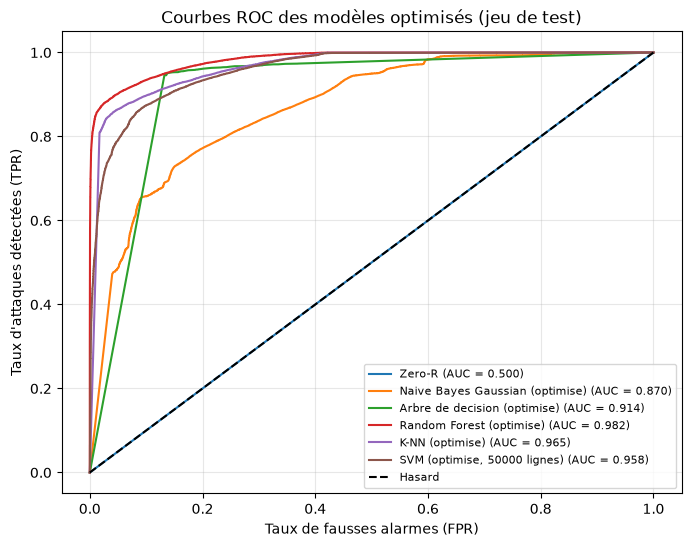

In [20]:
from sklearn.metrics import roc_curve


def scores_du_modele(modele):
    if hasattr(modele, "predict_proba"):
        return modele.predict_proba(X_test)[:, 1]
    return modele.decision_function(X_test)


modeles_roc = {
    "Zero-R": zero_r,
    "Naive Bayes Gaussian (optimise)": rech_gauss.best_estimator_,
    "Arbre de decision (optimise)": rech_arbre.best_estimator_,
    "Random Forest (optimise)": rf_opt,
    "K-NN (optimise)": knn_opt,
    "SVM (optimise, 50000 lignes)": svm_opt,
}

plt.figure(figsize=(8, 6))
for nom, modele in modeles_roc.items():
    s = scores_du_modele(modele)
    fpr, tpr, _ = roc_curve(y_test, s)
    plt.plot(fpr, tpr, label=f"{nom} (AUC = {roc_auc_score(y_test, s):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Hasard")
plt.xlabel("Taux de fausses alarmes (FPR)")
plt.ylabel("Taux d'attaques détectées (TPR)")
plt.title("Courbes ROC des modèles optimisés (jeu de test)")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.savefig("../docs/figures/courbes_roc.png", dpi=150, bbox_inches="tight")
plt.show()

,Modèle,Accuracy,Precision,Recall,F1,ROC-AUC
4,Random Forest,0.8728,0.8196,0.9860,0.8951,0.9796
12,Random Forest (optimise),0.8708,0.8159,0.9882,0.8939,0.9824
8,Arbre de decision (optimise),0.8718,0.8297,0.9651,0.8923,0.9135
3,Arbre de decision,0.8629,0.8241,0.9549,0.8847,0.8550
11,K-NN (optimise),0.8460,0.7917,0.9777,0.8749,0.9651
5,K-NN (k=5),0.8448,0.7966,0.9644,0.8725,0.9315
13,"SVM (optimise, 50000 lignes)",0.8152,0.7509,0.9941,0.8555,0.9583
7,SVM RBF (50000 lignes),0.8145,0.7501,0.9944,0.8551,0.9574
6,SVM lineaire (LinearSVC),0.8111,0.7504,0.9842,0.8516,0.9537
1,Naive Bayes (Gaussian),0.7693,0.8601,0.6939,0.7681,0.8698


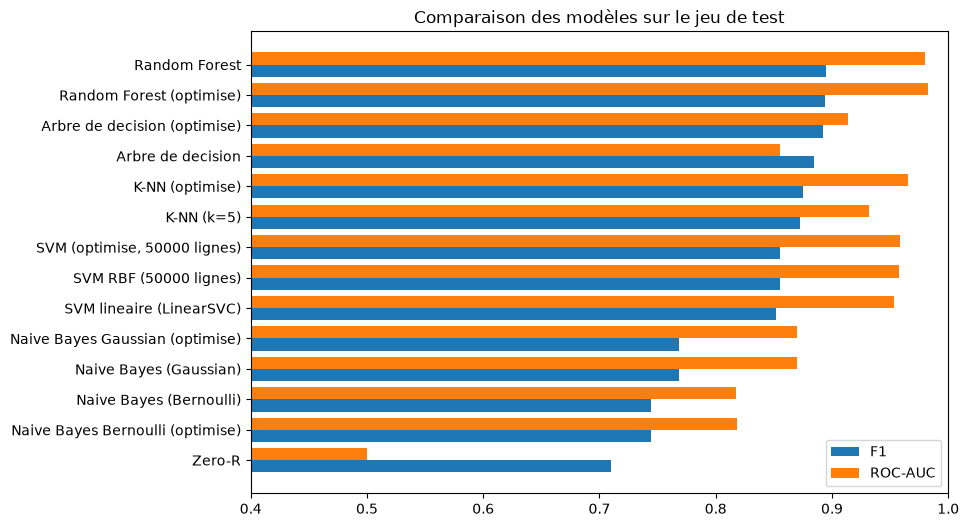

| Modèle | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| Random Forest | 0.8728 | 0.8196 | 0.986 | 0.8951 | 0.9796 |
| Random Forest (optimise) | 0.8708 | 0.8159 | 0.9882 | 0.8939 | 0.9824 |
| Arbre de decision (optimise) | 0.8718 | 0.8297 | 0.9651 | 0.8923 | 0.9135 |
| Arbre de decision | 0.8629 | 0.8241 | 0.9549 | 0.8847 | 0.855 |
| K-NN (optimise) | 0.846 | 0.7917 | 0.9777 | 0.8749 | 0.9651 |
| K-NN (k=5) | 0.8448 | 0.7966 | 0.9644 | 0.8725 | 0.9315 |
| SVM (optimise, 50000 lignes) | 0.8152 | 0.7509 | 0.9941 | 0.8555 | 0.9583 |
| SVM RBF (50000 lignes) | 0.8145 | 0.7501 | 0.9944 | 0.8551 | 0.9574 |
| SVM lineaire (LinearSVC) | 0.8111 | 0.7504 | 0.9842 | 0.8516 | 0.9537 |
| Naive Bayes (Gaussian) | 0.7693 | 0.8601 | 0.6939 | 0.7681 | 0.8698 |
| Naive Bayes Gaussian (optimise) | 0.7693 | 0.8601 | 0.6939 | 0.7681 | 0.8698 |
| Naive Bayes Bernoulli (optimise) | 0.7478 | 0.8418 | 0.6674 | 0.7445 | 0.8184 |
| Naive Bayes (Bernoulli) | 0.7478 | 0.8418 | 0

In [21]:
tableau = (pd.DataFrame(resultats).drop(columns=["Temps (s)"], errors="ignore")
           .sort_values("F1", ascending=False).round(4))
tableau.to_csv("../docs/tableau_comparatif.csv", index=False)
display(tableau)

# Graphique F1 et ROC-AUC
ordre = tableau.sort_values("F1")
y = np.arange(len(ordre))
plt.figure(figsize=(9, 6))
plt.barh(y - 0.2, ordre["F1"], height=0.4, label="F1")
plt.barh(y + 0.2, ordre["ROC-AUC"], height=0.4, label="ROC-AUC")
plt.yticks(y, ordre["Modèle"])
plt.xlim(0.4, 1.0)
plt.legend()
plt.title("Comparaison des modèles sur le jeu de test")
plt.savefig("../docs/figures/comparaison_modeles.png", dpi=150, bbox_inches="tight")
plt.show()

# Tableau prêt à coller dans le README
lignes = ["| Modèle | Accuracy | Precision | Recall | F1-score | ROC-AUC |", "|---|---|---|---|---|---|"]
for _, r in tableau.iterrows():
    lignes.append(f"| {r['Modèle']} | {r['Accuracy']} | {r['Precision']} | {r['Recall']} | {r['F1']} | {r['ROC-AUC']} |")
print("\n".join(lignes))